In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

In [2]:
raw_dir = Path("../data/raw/PSEO")
code_cols = ["agg_level_pseo", "inst_level", "institution", "degree_level", "cip_level",
             "cipcode", "grad_cohort", "grad_cohort_years", "geo_level", "geography",
             "ind_level", "industry"]
certificate_levels = ["01", "02", "04"]

pseoe_raw = pd.read_csv(raw_dir / "pseoe_all_2025.csv", dtype={c: str for c in code_cols})
pseoe = pseoe_raw[(pseoe_raw["agg_level_pseo"] == "42") & pseoe_raw["degree_level"].isin(certificate_levels)].copy()

print("PSEOE raw:", pseoe_raw.shape, "-> kept:", pseoe.shape)

PSEOE raw: (623084, 36) -> kept: (18826, 36)


In [3]:
pseof_full_path = raw_dir / "pseof_all_2025.csv"
pseof_extract_path = raw_dir / "pseof_certificates_2025.csv"

if not pseof_extract_path.exists():
    chunks = []
    for chunk in pd.read_csv(pseof_full_path, dtype={c: str for c in code_cols}, chunksize=5_000_000):
        keep = chunk["agg_level_pseo"].isin(["40", "88"]) & chunk["degree_level"].isin(certificate_levels)
        chunks.append(chunk[keep])
    pd.concat(chunks, ignore_index=True).to_csv(pseof_extract_path, index=False)
    print(f"Built extract from the full file: {pseof_extract_path}")

pseof = pd.read_csv(pseof_extract_path, dtype={c: str for c in code_cols})
print("PSEOF kept:", pseof.shape)

PSEOF kept: (200256, 30)


## Drop columns with no information
After filtering, geography, industry level (PSEOE), cohort and CIP level columns hold a single value. They're dropped from both files.

In [4]:
pseoe_constant = [c for c in pseoe.columns if pseoe[c].nunique(dropna=False) == 1]
pseof_constant = [c for c in pseof.columns if pseof[c].nunique(dropna=False) == 1]
print("PSEOE dropping:", pseoe_constant)
print("PSEOF dropping:", pseof_constant)

pseoe = pseoe.drop(columns=pseoe_constant)
pseof = pseof.drop(columns=pseof_constant)

PSEOE dropping: ['agg_level_pseo', 'inst_level', 'cip_level', 'grad_cohort', 'grad_cohort_years', 'geo_level', 'geography', 'ind_level', 'industry']
PSEOF dropping: ['inst_level', 'cip_level', 'grad_cohort', 'grad_cohort_years', 'geo_level', 'geography']


## Missing values: convert status flags
Every value has a status flag (LEHD schema) that explains **why** it's missing:
- `1` = ok
- `5` = **suppressed**: fewer than 30 graduates (common at small/rural colleges)
- `-1` = **not yet available**: the cohort hasn't reached 5 or 10 years yet

*NOTE: don't fill these with 0. A suppressed count means "fewer than 30", not zero.*

Flags that always match each other are collapsed into one readable column per year (e.g. all four earnings columns for year 1 share `y1_earnings_status`).

In [5]:
status_labels = {1: "ok", 5: "suppressed", -1: "not_yet_available"}

for y in ["y1", "y5", "y10"]:
    assert (pseoe[f"status_{y}_earnings"] == pseoe[f"status_{y}_grads_earn"]).all()
    pseoe[f"{y}_earnings_status"] = pseoe[f"status_{y}_earnings"].map(status_labels)

    assert (pseof[f"status_{y}_grads_emp"] == pseof[f"status_{y}_grads_emp_instate"]).all()
    pseof[f"{y}_emp_status"] = pseof[f"status_{y}_grads_emp"].map(status_labels)

pseoe = pseoe.drop(columns=[c for c in pseoe.columns if c.startswith("status_")])
pseof = pseof.drop(columns=[c for c in pseof.columns if c.startswith("status_")])

pseoe[["y1_earnings_status", "y5_earnings_status", "y10_earnings_status"]].apply(pd.Series.value_counts)

,y1_earnings_status,y5_earnings_status,y10_earnings_status
not_yet_available,NaN,3111,7195
ok,7830.0,6162,3456
suppressed,10996.0,9553,8175


## Truncate 4-digit CIP to 2-digit
- `CIP_family` = 4-digit CIP (`"51.39"`, Practical Nursing)
- `CIP_series` = 2-digit CIP (`"51"`, Health Professions), the first two characters of `CIP_family`

CIP codes are hierarchical, so truncating is exact: `51.39` is always part of `51`.

In [6]:
pseoe = pseoe.rename(columns={"cipcode": "CIP_family"})
pseoe["CIP_series"] = pseoe["CIP_family"].str[:2]
pseof = pseof.rename(columns={"cipcode": "CIP_series"})

pseoe[["CIP_family", "CIP_series"]].drop_duplicates().head()

,CIP_family,CIP_series
154210,16.09,16
154250,41.00,41
154276,51.06,51
154281,51.09,51
154284,51.10,51


## Employment features from PSEOF (2-digit CIP)
From the all-industries rows (`agg_level_pseo == "40"`):
- `emp_rate` = employed / (employed + not meaningfully employed): proxy for Workforce Pell's **70% job placement** test
- `instate_rate` = share of employed graduates working in the institution's state

In [7]:
merge_keys = ["institution", "degree_level", "CIP_series"]

emp = pseof[pseof["agg_level_pseo"] == "40"].copy()
emp = emp[merge_keys + [c for c in emp.columns if c.startswith(("y1_", "y5_", "y10_"))]]

for y in ["y1", "y5", "y10"]:
    emp[f"{y}_emp_rate"] = emp[f"{y}_grads_emp"] / (emp[f"{y}_grads_emp"] + emp[f"{y}_grads_nme"])
emp["y1_instate_rate"] = emp["y1_grads_emp_instate"] / emp["y1_grads_emp"]

emp[["y1_emp_rate", "y5_emp_rate", "y1_instate_rate"]].describe().round(2)

,y1_emp_rate,y5_emp_rate,y1_instate_rate
count,5780.00,4547.00,5774.00
mean,0.69,0.74,0.63
std,0.19,0.16,0.26
min,0.00,0.00,0.00
25%,0.58,0.66,0.42
50%,0.71,0.76,0.67
75%,0.82,0.85,0.86
max,1.00,1.00,1.00


In [8]:
industry_names = {
    "11": "Agriculture, Forestry, Fishing and Hunting", "21": "Mining, Quarrying, and Oil and Gas Extraction",
    "22": "Utilities", "23": "Construction", "31-33": "Manufacturing", "42": "Wholesale Trade",
    "44-45": "Retail Trade", "48-49": "Transportation and Warehousing", "51": "Information",
    "52": "Finance and Insurance", "53": "Real Estate and Rental and Leasing",
    "54": "Professional, Scientific, and Technical Services", "55": "Management of Companies and Enterprises",
    "56": "Administrative and Support and Waste Management", "61": "Educational Services",
    "62": "Health Care and Social Assistance", "71": "Arts, Entertainment, and Recreation",
    "72": "Accommodation and Food Services", "81": "Other Services (except Public Administration)",
    "92": "Public Administration",
}

ind = pseof[pseof["agg_level_pseo"] == "88"][merge_keys + ["industry", "y1_grads_emp"]]
ind = ind.merge(emp[merge_keys + ["y1_grads_emp"]], on=merge_keys, suffixes=("", "_total"))
ind["share"] = ind["y1_grads_emp"] / ind["y1_grads_emp_total"]

shares = ind.pivot_table(index=merge_keys, columns="industry", values="share")
shares.columns = ["y1_share_" + c.replace("-", "_") for c in shares.columns]

top = ind.dropna(subset=["share"]).sort_values("share", ascending=False).drop_duplicates(merge_keys)
top = top.set_index(merge_keys)[["industry", "share"]]
top.columns = ["y1_top_industry", "y1_top_industry_share"]
top["y1_top_industry_name"] = top["y1_top_industry"].map(industry_names)

industry_features = shares.join(top).reset_index()
print(industry_features.shape)
industry_features.head()

(5774, 26)


,institution,degree_level,CIP_series,y1_share_11,y1_share_21,y1_share_22,y1_share_23,y1_share_31_33,y1_share_42,y1_share_44_45,y1_share_48_49,y1_share_51,y1_share_52,y1_share_53,y1_share_54,y1_share_55,y1_share_56,y1_share_61,y1_share_62,y1_share_71,y1_share_72,y1_share_81,y1_share_92,y1_top_industry,y1_top_industry_share,y1_top_industry_name
0,00105200,02,16,0.043478,0.028986,0.014493,0.000000,0.086957,0.000000,0.043478,0.014493,0.028986,0.028986,0.028986,0.086957,0.028986,0.000000,0.159420,0.188406,0.000000,0.086957,0.115942,0.014493,62,0.188406,Health Care and Social Assistance
1,00105200,02,51,0.000000,0.000000,0.000000,0.000000,0.003937,0.000000,0.043307,0.000000,0.003937,0.027559,0.000000,0.023622,0.000000,0.007874,0.082677,0.787402,0.000000,0.007874,0.007874,0.003937,62,0.787402,Health Care and Social Assistance
2,00105200,02,52,0.000000,0.000000,0.003155,0.037855,0.091483,0.148265,0.082019,0.022082,0.025237,0.082019,0.025237,0.104101,0.044164,0.050473,0.053628,0.094637,0.012618,0.053628,0.037855,0.031546,42,0.148265,Wholesale Trade
3,00108200,01,51,0.000000,0.000000,0.000000,0.004320,0.004320,0.012959,0.041037,0.004320,0.000000,0.028078,0.004320,0.019438,0.002160,0.023758,0.436285,0.334773,0.000000,0.053996,0.002160,0.028078,61,0.436285,Educational Services
4,00108200,01,52,0.001089,0.002179,0.003268,0.029412,0.045207,0.027778,0.071351,0.016885,0.023965,0.218954,0.035403,0.141068,0.019608,0.056100,0.069172,0.052288,0.016885,0.125272,0.010349,0.033769,52,0.218954,Finance and Insurance


## Combine PSEOE and PSEOF on the 2-digit CIP


In [9]:
pseof_features = emp.merge(industry_features, on=merge_keys, how="left")
pseof_features = pseof_features.rename(columns={c: f"{c}_cip2" for c in pseof_features.columns if c not in merge_keys})

pseo = pseoe.merge(pseof_features, on=merge_keys, how="left")

assert len(pseo) == len(pseoe)
assert not pseo.duplicated(["institution", "degree_level", "CIP_family"]).any()
print(pseo.shape)
print(f"Programs with PSEOF employment data: {pseo['y1_grads_emp_cip2'].notna().mean():.0%}")

(18826, 61)
Programs with PSEOF employment data: 74%


## Labels and derived features


In [10]:
institutions = pd.read_csv(raw_dir / "pseo_all_institutions_2025.csv", dtype=str, encoding="utf-8-sig")
institutions = institutions.rename(columns={"label": "institution_name", "institution_state": "state"})
pseo = pseo.merge(institutions[["institution", "institution_name", "state"]], on="institution", how="left")
pseo["OPEID6"] = pseo["institution"].str[:6].str.lstrip("0")

degree_labels = {"01": "Certificate < 1 year", "02": "Certificate 1-2 years", "04": "Certificate 2-4 years"}
pseo["degree_level_label"] = pseo["degree_level"].map(degree_labels)
pseo["is_short_term_cert"] = (pseo["degree_level"] == "01").astype(int)

cip_series_names = {
    "01": "Agriculture", "03": "Natural Resources", "04": "Architecture", "05": "Area & Ethnic Studies",
    "09": "Communication", "10": "Communications Technologies", "11": "Computer & Info Sciences",
    "12": "Personal & Culinary Services", "13": "Education", "14": "Engineering",
    "15": "Engineering Technologies", "16": "Foreign Languages", "19": "Family & Consumer Sciences",
    "22": "Legal Professions", "23": "English", "24": "Liberal Arts & General Studies",
    "25": "Library Science", "26": "Biological Sciences", "27": "Mathematics", "29": "Military Technologies",
    "30": "Multi/Interdisciplinary", "31": "Parks, Recreation & Fitness", "32": "Basic Skills",
    "38": "Philosophy & Religion", "39": "Theology", "40": "Physical Sciences", "41": "Science Technologies",
    "42": "Psychology", "43": "Security & Protective Services", "44": "Public Admin & Social Service",
    "45": "Social Sciences", "46": "Construction Trades", "47": "Mechanic & Repair Technologies",
    "48": "Precision Production", "49": "Transportation & Materials Moving", "50": "Visual & Performing Arts",
    "51": "Health Professions", "52": "Business & Marketing", "54": "History",
}
pseo["CIP_series_name"] = pseo["CIP_series"].map(cip_series_names).fillna("CIP " + pseo["CIP_series"])

pseo["earn_growth_y1_y5"] = pseo["y5_p50_earnings"] / pseo["y1_p50_earnings"]
pseo["earn_spread_y1"] = (pseo["y1_p75_earnings"] - pseo["y1_p25_earnings"]) / pseo["y1_p50_earnings"]

id_cols = ["institution", "OPEID6", "institution_name", "state", "degree_level", "degree_level_label",
           "is_short_term_cert", "CIP_family", "CIP_series", "CIP_series_name"]
pseo = pseo[id_cols + [c for c in pseo.columns if c not in id_cols]]
pseo.head()

,institution,OPEID6,institution_name,state,degree_level,degree_level_label,is_short_term_cert,CIP_family,CIP_series,CIP_series_name,y1_p25_earnings,y1_p50_earnings,y1_p75_earnings,y1_grads_earn,y5_p25_earnings,y5_p50_earnings,y5_p75_earnings,y5_grads_earn,y10_p25_earnings,y10_p50_earnings,y10_p75_earnings,y10_grads_earn,y1_ipeds_count,y5_ipeds_count,y10_ipeds_count,y1_earnings_status,y5_earnings_status,y10_earnings_status,y1_grads_emp_cip2,y1_grads_emp_instate_cip2,y5_grads_emp_cip2,y5_grads_emp_instate_cip2,y10_grads_emp_cip2,y10_grads_emp_instate_cip2,y1_grads_nme_cip2,y5_grads_nme_cip2,y10_grads_nme_cip2,y1_emp_status_cip2,y5_emp_status_cip2,y10_emp_status_cip2,y1_emp_rate_cip2,y5_emp_rate_cip2,y10_emp_rate_cip2,y1_instate_rate_cip2,y1_share_11_cip2,y1_share_21_cip2,y1_share_22_cip2,y1_share_23_cip2,y1_share_31_33_cip2,y1_share_42_cip2,y1_share_44_45_cip2,y1_share_48_49_cip2,y1_share_51_cip2,y1_share_52_cip2,y1_share_53_cip2,y1_share_54_cip2,y1_share_55_cip2,y1_share_56_cip2,y1_share_61_cip2,y1_share_62_cip2,y1_share_71_cip2,y1_share_72_cip2,y1_share_81_cip2,y1_share_92_cip2,y1_top_industry_cip2,y1_top_industry_share_cip2,y1_top_industry_name_cip2,earn_growth_y1_y5,earn_spread_y1
0,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,16.09,16,Foreign Languages,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,NaN,NaN,suppressed,suppressed,not_yet_available,69.0,11.0,41.0,22.0,NaN,NaN,19.0,11.0,NaN,ok,ok,not_yet_available,0.784091,0.788462,NaN,0.159420,0.043478,0.028986,0.014493,0.0,0.086957,0.0,0.043478,0.014493,0.028986,0.028986,0.028986,0.086957,0.028986,0.000000,0.159420,0.188406,0.0,0.086957,0.115942,0.014493,62,0.188406,Health Care and Social Assistance,NaN,NaN
1,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,41.00,41,Science Technologies,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,suppressed,not_yet_available,not_yet_available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,suppressed,not_yet_available,not_yet_available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,51.06,51,Health Professions,24086.0,28181.0,33220.0,104.0,29102.0,38181.0,44990.0,77.0,NaN,NaN,NaN,NaN,257.0,188.0,90.0,ok,ok,suppressed,254.0,212.0,267.0,194.0,52.0,33.0,74.0,60.0,10.0,ok,ok,ok,0.774390,0.816514,0.83871,0.834646,0.000000,0.000000,0.000000,0.0,0.003937,0.0,0.043307,0.000000,0.003937,0.027559,0.000000,0.023622,0.000000,0.007874,0.082677,0.787402,0.0,0.007874,0.007874,0.003937,62,0.787402,Health Care and Social Assistance,1.354849,0.324119
3,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,51.09,51,Health Professions,41093.0,50831.0,59550.0,114.0,50767.0,61511.0,73014.0,117.0,55060.0,69727.0,95990.0,39.0,0.0,0.0,0.0,ok,ok,ok,254.0,212.0,267.0,194.0,52.0,33.0,74.0,60.0,10.0,ok,ok,ok,0.774390,0.816514,0.83871,0.834646,0.000000,0.000000,0.000000,0.0,0.003937,0.0,0.043307,0.000000,0.003937,0.027559,0.000000,0.023622,0.000000,0.007874,0.082677,0.787402,0.0,0.007874,0.007874,0.003937,62,0.787402,Health Care and Social Assistance,1.210108,0.363105
4,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,51.10,51,Health Professions,43626.0,57769.0,64754.0,45.0,56524.0,63134.0,71728.0,47.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ok,ok,suppressed,254.0,212.0,267.0,194.0,52.0,33.0,74.0,60.0,10.0,ok,ok,ok,0.774390,0.816514,0.83871,0.834646,0.000000,0.000000,0.000000,0.0,0.003937,0.0,0.043307,0.000000,0.003937,0.027559,0.000000,0.023622,0.000000,0.007874,0.082677,0.787402,0.0,0.007874,0.007874,0.003937,62,0.787402,Health Care and Social Assistance,1.092870,0.365732


## Missing Values Analysis
### % missing by feature

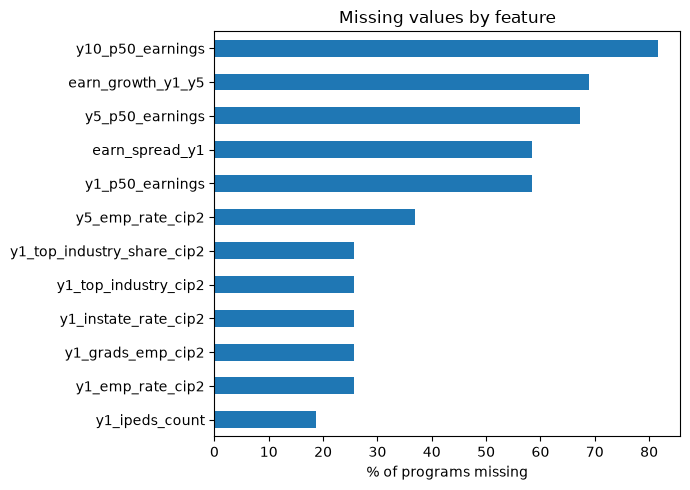

,pct_missing
y1_ipeds_count,18.7
y1_emp_rate_cip2,25.6
y1_grads_emp_cip2,25.6
y1_instate_rate_cip2,25.7
y1_top_industry_cip2,25.7
y1_top_industry_share_cip2,25.7
y5_emp_rate_cip2,36.9
y1_p50_earnings,58.4
earn_spread_y1,58.4
y5_p50_earnings,67.3


In [11]:
key_features = ["y1_p50_earnings", "y5_p50_earnings", "y10_p50_earnings", "y1_ipeds_count",
                "earn_growth_y1_y5", "earn_spread_y1", "y1_grads_emp_cip2", "y1_emp_rate_cip2",
                "y5_emp_rate_cip2", "y1_instate_rate_cip2", "y1_top_industry_cip2", "y1_top_industry_share_cip2"]
missing = pseo[key_features].isna().mean().mul(100).round(1).sort_values()

missing.plot.barh(figsize=(7, 5))
plt.xlabel("% of programs missing")
plt.title("Missing values by feature")
plt.tight_layout()
plt.show()
missing.to_frame("pct_missing")

### Why values are missing (% of programs)

In [12]:
status_cols = ["y1_earnings_status", "y5_earnings_status", "y10_earnings_status",
               "y1_emp_status_cip2", "y5_emp_status_cip2", "y10_emp_status_cip2"]
pseo[status_cols].apply(lambda s: s.value_counts(normalize=True, dropna=False)).T.mul(100).round(1).fillna(0)

,not_yet_available,ok,suppressed
y1_earnings_status,0.0,41.6,58.4
y5_earnings_status,16.5,32.7,50.7
y10_earnings_status,38.2,18.4,43.4
y1_emp_status_cip2,0.0,74.4,25.6
y5_emp_status_cip2,8.1,63.1,28.8
y10_emp_status_cip2,23.7,42.3,34.0


### Missing Data
- **Year 1 is the most complete outcome.** Year 10 earnings are mostly missing, partly because recent cohorts haven't reached 10 years yet.
- **Missing earnings are not random: small programs get suppressed** (chart below). Dropping rows with missing earnings would drop most small, often rural, programs.
- `NaN` in a `_cip2` column with no status means the 2-digit field had no PSEOF row for that institution.

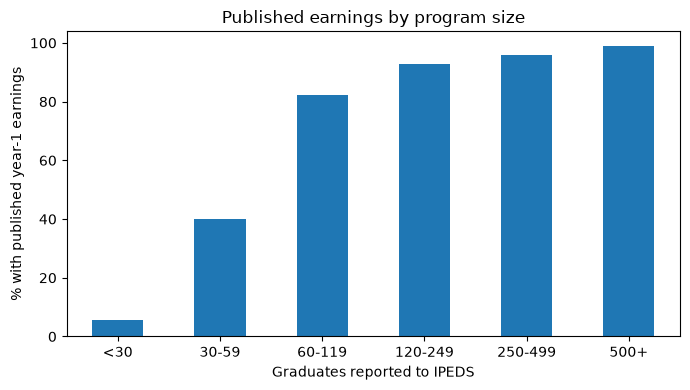

In [13]:
size_bucket = pd.cut(pseo["y1_ipeds_count"], [0, 30, 60, 120, 250, 500, np.inf],
                     labels=["<30", "30-59", "60-119", "120-249", "250-499", "500+"], right=False)
published = pseo.groupby(size_bucket, observed=True)["y1_earnings_status"].apply(lambda s: (s == "ok").mean() * 100)

published.plot.bar(figsize=(7, 4), rot=0)
plt.xlabel("Graduates reported to IPEDS")
plt.ylabel("% with published year-1 earnings")
plt.title("Published earnings by program size")
plt.tight_layout()
plt.show()

## Key relationships
### Year-1 earnings by certificate length

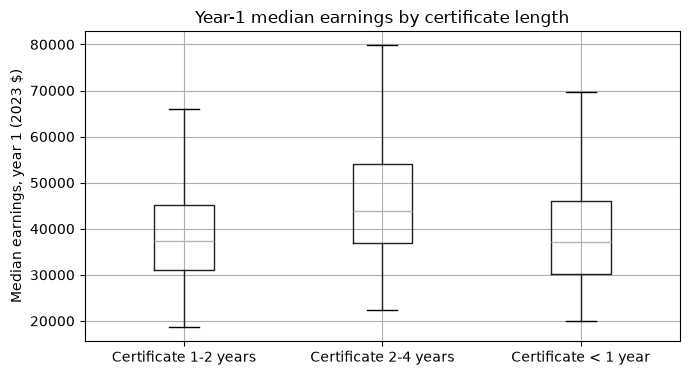

In [14]:
pseo.boxplot(column="y1_p50_earnings", by="degree_level_label", showfliers=False, figsize=(7, 4))
plt.suptitle("")
plt.title("Year-1 median earnings by certificate length")
plt.xlabel("")
plt.ylabel("Median earnings, year 1 (2023 $)")
plt.tight_layout()
plt.show()

### Employment rate vs. earnings
The two outcome tests behind an `is_pell_aligned` label. Employment rate is for the 2-digit field, so programs in the same field at the same institution line up vertically.

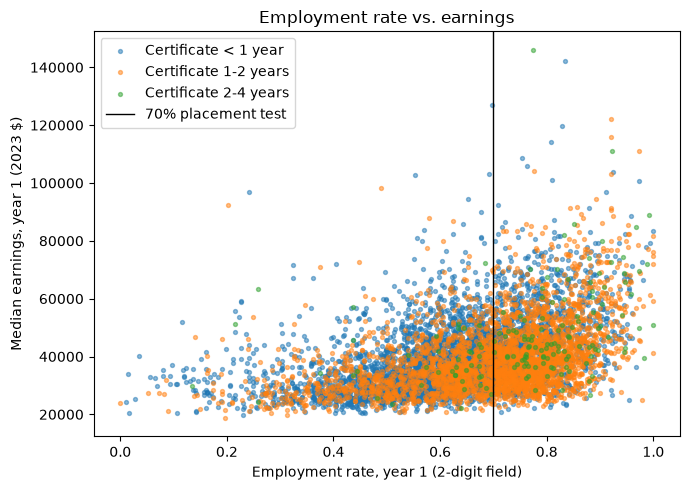

In [15]:
plt.figure(figsize=(7, 5))
for label in degree_labels.values():
    s = pseo[pseo["degree_level_label"] == label]
    plt.scatter(s["y1_emp_rate_cip2"], s["y1_p50_earnings"], s=8, alpha=0.5, label=label)
plt.axvline(0.70, color="black", linewidth=1, label="70% placement test")
plt.xlabel("Employment rate, year 1 (2-digit field)")
plt.ylabel("Median earnings, year 1 (2023 $)")
plt.title("Employment rate vs. earnings")
plt.legend()
plt.tight_layout()
plt.show()

### Year-1 earnings by field (fields with 40+ programs)

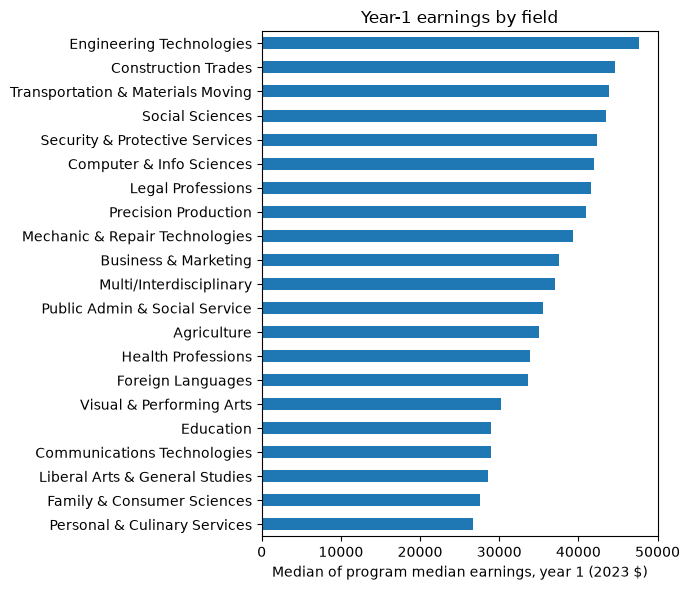

In [16]:
by_field = (pseo.dropna(subset=["y1_p50_earnings"]).groupby("CIP_series_name")["y1_p50_earnings"]
            .agg(["median", "count"]).query("count >= 40").sort_values("median"))

by_field["median"].plot.barh(figsize=(7, 6))
plt.xlabel("Median of program median earnings, year 1 (2023 $)")
plt.ylabel("")
plt.title("Year-1 earnings by field")
plt.tight_layout()
plt.show()

<1 year certificate programs: 10,025 at 512 schools in 25 states


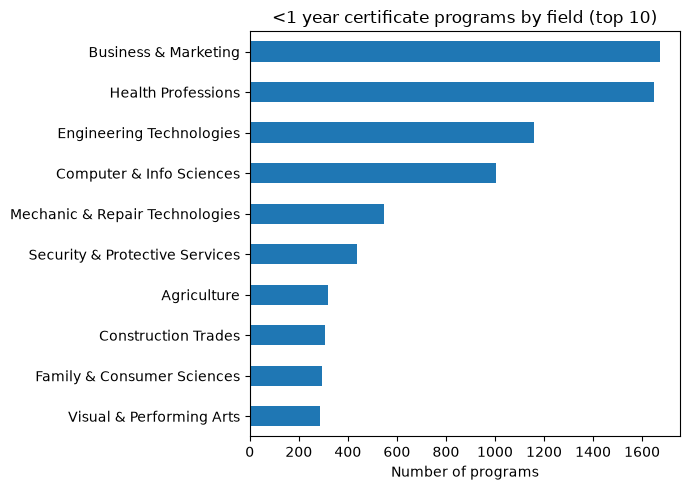

,programs
state,
TX,1547
IL,1442
OH,921
IN,766
MN,750
CO,633


In [17]:
one_year_certs = pseo[pseo["degree_level"] == "01"]
print(f"<1 year certificate programs: {len(one_year_certs):,} at {one_year_certs['institution'].nunique()} schools in {one_year_certs['state'].nunique()} states")

one_year_certs["CIP_series_name"].value_counts().head(10).sort_values().plot.barh(figsize=(7, 5))
plt.xlabel("Number of programs")
plt.ylabel("")
plt.title("<1 year certificate programs by field (top 10)")
plt.tight_layout()
plt.show()

one_year_certs["state"].value_counts().head(6).to_frame("programs")

1-2 year certificate programs: 8,322 at 573 schools in 29 states


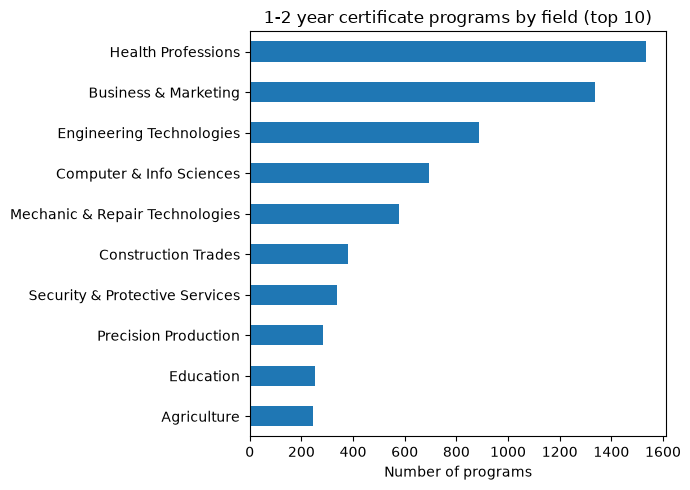

,programs
state,
IL,1157
OH,747
NY,621
IN,565
MN,561
TX,504


In [18]:
two_year_certs = pseo[pseo["degree_level"] == "02"]
print(f"1-2 year certificate programs: {len(two_year_certs):,} at {two_year_certs['institution'].nunique()} schools in {two_year_certs['state'].nunique()} states")

two_year_certs["CIP_series_name"].value_counts().head(10).sort_values().plot.barh(figsize=(7, 5))
plt.xlabel("Number of programs")
plt.ylabel("")
plt.title("1-2 year certificate programs by field (top 10)")
plt.tight_layout()
plt.show()

two_year_certs["state"].value_counts().head(6).to_frame("programs")

2-4 year certificate programs: 479 at 118 schools in 18 states


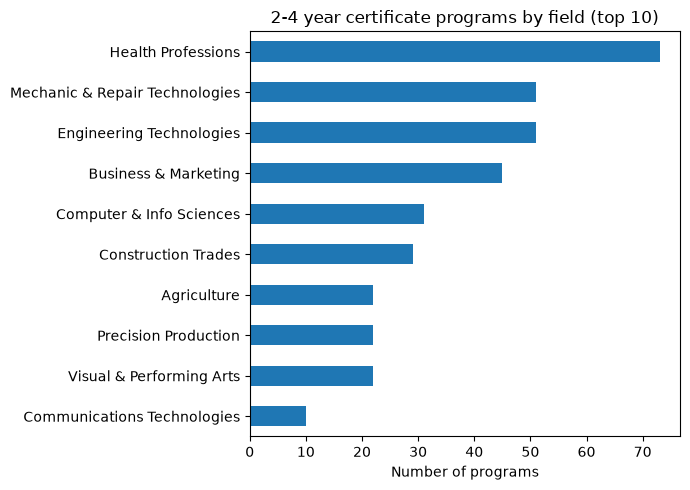

,programs
state,
MN,209
TX,121
MO,34
MT,26
OR,24
CT,12


In [19]:
long_certs = pseo[pseo["degree_level"] == "04"]
print(f"2-4 year certificate programs: {len(long_certs):,} at {long_certs['institution'].nunique()} schools in {long_certs['state'].nunique()} states")

long_certs["CIP_series_name"].value_counts().head(10).sort_values().plot.barh(figsize=(7, 5))
plt.xlabel("Number of programs")
plt.ylabel("")
plt.title("2-4 year certificate programs by field (top 10)")
plt.tight_layout()
plt.show()

long_certs["state"].value_counts().head(6).to_frame("programs")

### Where graduates work: field × industry
Average share of employed graduates (year 1) in each sector, for the 10 largest fields and 10 most common sectors. Each institution × field is counted once.

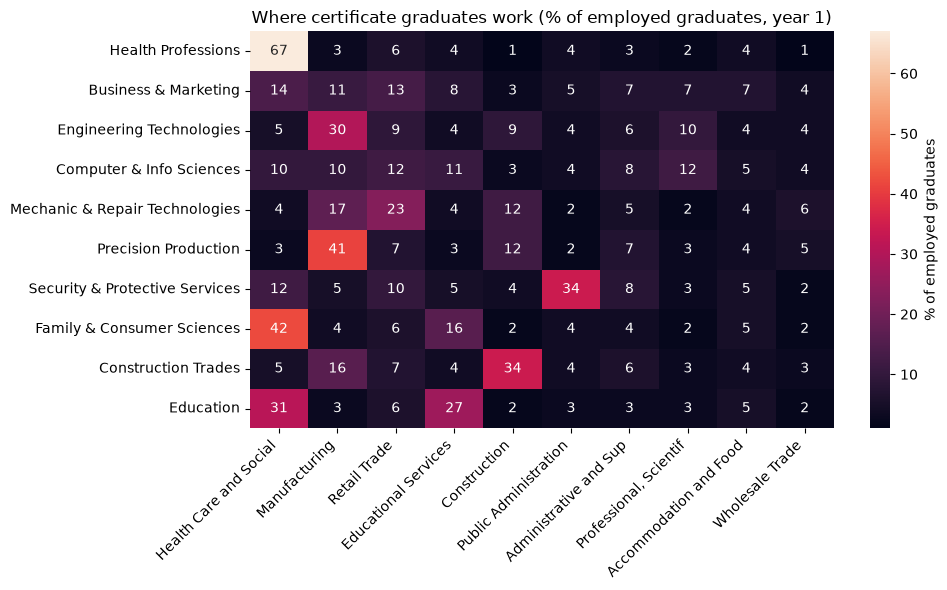

,Health Care and Social,Manufacturing,Retail Trade,Educational Services,Construction,Public Administration,Administrative and Sup,"Professional, Scientif",Accommodation and Food,Wholesale Trade
CIP_series_name,,,,,,,,,,
Health Professions,67.0,3.0,6.0,4.0,1.0,4.0,3.0,2.0,4.0,1.0
Business & Marketing,14.0,11.0,13.0,8.0,3.0,5.0,7.0,7.0,7.0,4.0
Engineering Technologies,5.0,30.0,9.0,4.0,9.0,4.0,6.0,10.0,4.0,4.0
Computer & Info Sciences,10.0,10.0,12.0,11.0,3.0,4.0,8.0,12.0,5.0,4.0
Mechanic & Repair Technologies,4.0,17.0,23.0,4.0,12.0,2.0,5.0,2.0,4.0,6.0
Precision Production,3.0,41.0,7.0,3.0,12.0,2.0,7.0,3.0,4.0,5.0
Security & Protective Services,12.0,5.0,10.0,5.0,4.0,34.0,8.0,3.0,5.0,2.0
Family & Consumer Sciences,42.0,4.0,6.0,16.0,2.0,4.0,4.0,2.0,5.0,2.0
Construction Trades,5.0,16.0,7.0,4.0,34.0,4.0,6.0,3.0,4.0,3.0


In [20]:
share_cols = [c for c in pseo.columns if c.startswith("y1_share_")]
field_level = pseo.drop_duplicates(["institution", "degree_level", "CIP_series"])
top_fields = field_level["CIP_series_name"].value_counts().head(10).index

table = field_level[field_level["CIP_series_name"].isin(top_fields)].groupby("CIP_series_name")[share_cols].mean().mul(100)
top_sectors = table.mean().sort_values(ascending=False).head(10).index
table = table.loc[top_fields, top_sectors].round(0)
table.columns = [industry_names[c.replace("y1_share_", "").replace("_cip2", "").replace("_", "-")][:22] for c in table.columns]

import seaborn as sns

plt.figure(figsize=(10, 6))
sns.heatmap(table, annot=True, fmt=".0f", cbar_kws={"label": "% of employed graduates"})
plt.xticks(rotation=45, ha="right")
plt.xlabel("")
plt.ylabel("")
plt.title("Where certificate graduates work (% of employed graduates, year 1)")
plt.tight_layout()
plt.show()
table

### Correlation between features (Spearman)

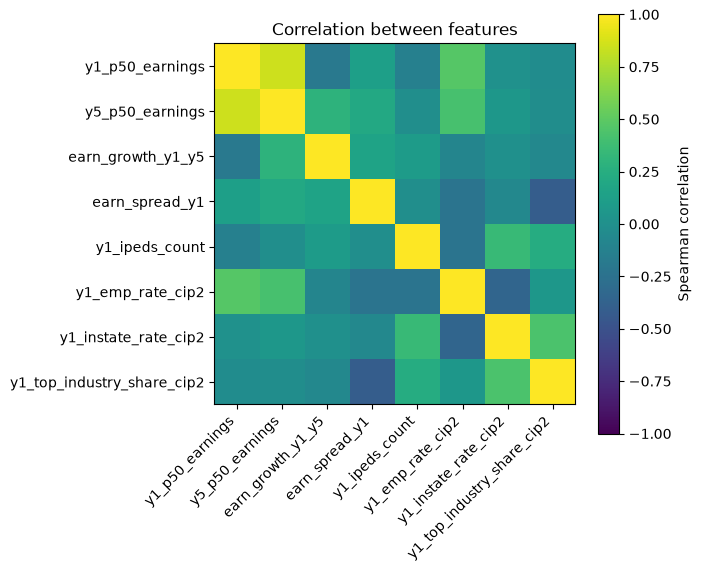

,y1_p50_earnings,y5_p50_earnings,earn_growth_y1_y5,earn_spread_y1,y1_ipeds_count,y1_emp_rate_cip2,y1_instate_rate_cip2,y1_top_industry_share_cip2
y1_p50_earnings,1.00,0.85,-0.19,0.13,-0.13,0.47,0.01,-0.03
y5_p50_earnings,0.85,1.00,0.29,0.21,-0.01,0.42,0.06,-0.02
earn_growth_y1_y5,-0.19,0.29,1.00,0.16,0.10,-0.09,-0.00,-0.07
earn_spread_y1,0.13,0.21,0.16,1.00,-0.01,-0.23,-0.07,-0.41
y1_ipeds_count,-0.13,-0.01,0.10,-0.01,1.00,-0.23,0.35,0.24
y1_emp_rate_cip2,0.47,0.42,-0.09,-0.23,-0.23,1.00,-0.35,0.06
y1_instate_rate_cip2,0.01,0.06,-0.00,-0.07,0.35,-0.35,1.00,0.43
y1_top_industry_share_cip2,-0.03,-0.02,-0.07,-0.41,0.24,0.06,0.43,1.00


In [21]:
corr_cols = ["y1_p50_earnings", "y5_p50_earnings", "earn_growth_y1_y5", "earn_spread_y1", "y1_ipeds_count",
             "y1_emp_rate_cip2", "y1_instate_rate_cip2", "y1_top_industry_share_cip2"]
corr = pseo[corr_cols].corr(method="spearman").round(2)

plt.figure(figsize=(7, 6))
plt.imshow(corr, vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation between features")
plt.tight_layout()
plt.show()
corr

## Save cleaned dataset

In [22]:
output_path = Path("../data/processed/PSEO_cleaned.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

pseo.to_csv(output_path, index=False)

print(f"Saved cleaned dataset to: {output_path}")
print("Final shape:", pseo.shape)

Saved cleaned dataset to: ..\data\processed\PSEO_cleaned.csv
Final shape: (18826, 69)


In [23]:
code_dtypes = {"institution": str, "OPEID6": str, "degree_level": str, "CIP_family": str,
               "CIP_series": str, "y1_top_industry_cip2": str}
df_check = pd.read_csv(output_path, dtype=code_dtypes)

print(df_check.shape)
print("Duplicates:", df_check.duplicated(["institution", "degree_level", "CIP_family"]).sum())
print("CIP_family examples:", df_check["CIP_family"].head(3).tolist(), "| CIP_series:", df_check["CIP_series"].head(3).tolist())

df_check.head()

(18826, 69)
Duplicates: 0
CIP_family examples: ['16.09', '41.00', '51.06'] | CIP_series: ['16', '41', '51']


,institution,OPEID6,institution_name,state,degree_level,degree_level_label,is_short_term_cert,CIP_family,CIP_series,CIP_series_name,y1_p25_earnings,y1_p50_earnings,y1_p75_earnings,y1_grads_earn,y5_p25_earnings,y5_p50_earnings,y5_p75_earnings,y5_grads_earn,y10_p25_earnings,y10_p50_earnings,y10_p75_earnings,y10_grads_earn,y1_ipeds_count,y5_ipeds_count,y10_ipeds_count,y1_earnings_status,y5_earnings_status,y10_earnings_status,y1_grads_emp_cip2,y1_grads_emp_instate_cip2,y5_grads_emp_cip2,y5_grads_emp_instate_cip2,y10_grads_emp_cip2,y10_grads_emp_instate_cip2,y1_grads_nme_cip2,y5_grads_nme_cip2,y10_grads_nme_cip2,y1_emp_status_cip2,y5_emp_status_cip2,y10_emp_status_cip2,y1_emp_rate_cip2,y5_emp_rate_cip2,y10_emp_rate_cip2,y1_instate_rate_cip2,y1_share_11_cip2,y1_share_21_cip2,y1_share_22_cip2,y1_share_23_cip2,y1_share_31_33_cip2,y1_share_42_cip2,y1_share_44_45_cip2,y1_share_48_49_cip2,y1_share_51_cip2,y1_share_52_cip2,y1_share_53_cip2,y1_share_54_cip2,y1_share_55_cip2,y1_share_56_cip2,y1_share_61_cip2,y1_share_62_cip2,y1_share_71_cip2,y1_share_72_cip2,y1_share_81_cip2,y1_share_92_cip2,y1_top_industry_cip2,y1_top_industry_share_cip2,y1_top_industry_name_cip2,earn_growth_y1_y5,earn_spread_y1
0,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,16.09,16,Foreign Languages,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,NaN,NaN,suppressed,suppressed,not_yet_available,69.0,11.0,41.0,22.0,NaN,NaN,19.0,11.0,NaN,ok,ok,not_yet_available,0.784091,0.788462,NaN,0.159420,0.043478,0.028986,0.014493,0.0,0.086957,0.0,0.043478,0.014493,0.028986,0.028986,0.028986,0.086957,0.028986,0.000000,0.159420,0.188406,0.0,0.086957,0.115942,0.014493,62,0.188406,Health Care and Social Assistance,NaN,NaN
1,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,41.00,41,Science Technologies,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,suppressed,not_yet_available,not_yet_available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,suppressed,not_yet_available,not_yet_available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,51.06,51,Health Professions,24086.0,28181.0,33220.0,104.0,29102.0,38181.0,44990.0,77.0,NaN,NaN,NaN,NaN,257.0,188.0,90.0,ok,ok,suppressed,254.0,212.0,267.0,194.0,52.0,33.0,74.0,60.0,10.0,ok,ok,ok,0.774390,0.816514,0.83871,0.834646,0.000000,0.000000,0.000000,0.0,0.003937,0.0,0.043307,0.000000,0.003937,0.027559,0.000000,0.023622,0.000000,0.007874,0.082677,0.787402,0.0,0.007874,0.007874,0.003937,62,0.787402,Health Care and Social Assistance,1.354849,0.324119
3,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,51.09,51,Health Professions,41093.0,50831.0,59550.0,114.0,50767.0,61511.0,73014.0,117.0,55060.0,69727.0,95990.0,39.0,0.0,0.0,0.0,ok,ok,ok,254.0,212.0,267.0,194.0,52.0,33.0,74.0,60.0,10.0,ok,ok,ok,0.774390,0.816514,0.83871,0.834646,0.000000,0.000000,0.000000,0.0,0.003937,0.0,0.043307,0.000000,0.003937,0.027559,0.000000,0.023622,0.000000,0.007874,0.082677,0.787402,0.0,0.007874,0.007874,0.003937,62,0.787402,Health Care and Social Assistance,1.210108,0.363105
4,00105200,1052,University of Alabama at Birmingham,AL,02,Certificate 1-2 years,0,51.10,51,Health Professions,43626.0,57769.0,64754.0,45.0,56524.0,63134.0,71728.0,47.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ok,ok,suppressed,254.0,212.0,267.0,194.0,52.0,33.0,74.0,60.0,10.0,ok,ok,ok,0.774390,0.816514,0.83871,0.834646,0.000000,0.000000,0.000000,0.0,0.003937,0.0,0.043307,0.000000,0.003937,0.027559,0.000000,0.023622,0.000000,0.007874,0.082677,0.787402,0.0,0.007874,0.007874,0.003937,62,0.787402,Health Care and Social Assistance,1.092870,0.365732
